## Classification

Predicts category rather than continous numbers

Outcome:
- Two Target Classes:
  - 0 -
  - 1 -

### Logistic Regression:
- S shaped Curve - 0 to 1 or 1 to 0.
- It works based on Sigmoid function
- Finds threshold value. Threshold value is used to split from one category to another. It is calculated using Sigmoid function.
- Sigmoid Function is used to convert numerical value to probability betweeen 0 and 1 using threshold value.
- 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv(r"loan_approval.csv")
df.head()

,age,annual_income_lakh,credit_score,loan_amount_lakh,existing_emis,loan_approved
0,24,7.1,480,5.0,1,0
1,51,7.8,544,8.1,0,0
2,47,7.2,613,8.2,3,0
3,38,8.8,635,5.7,0,1
4,38,17.0,647,30.4,1,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 600 non-null    int64  
 1   annual_income_lakh  600 non-null    float64
 2   credit_score        600 non-null    int64  
 3   loan_amount_lakh    600 non-null    float64
 4   existing_emis       600 non-null    int64  
 5   loan_approved       600 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 28.3 KB


In [5]:
df.isnull().sum()

age                   0
annual_income_lakh    0
credit_score          0
loan_amount_lakh      0
existing_emis         0
loan_approved         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe().round(2)

,age,annual_income_lakh,credit_score,loan_amount_lakh,existing_emis,loan_approved
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,40.52,9.09,680.73,14.78,2.43,0.55
std,11.60,4.78,81.91,10.52,1.75,0.50
min,21.00,2.00,400.00,1.10,0.00,0.00
25%,30.00,5.70,629.50,6.90,1.00,0.00
50%,40.00,8.20,682.50,12.45,2.00,1.00
75%,51.00,11.20,732.25,19.80,4.00,1.00
max,60.00,40.00,900.00,60.00,5.00,1.00


In [11]:
# Count rejected and approved loan with label name

print(df["loan_approved"].value_counts().rename(index = {0 : "Rejected", 1 : "Approved"}))

loan_approved
Approved    332
Rejected    268
Name: count, dtype: int64


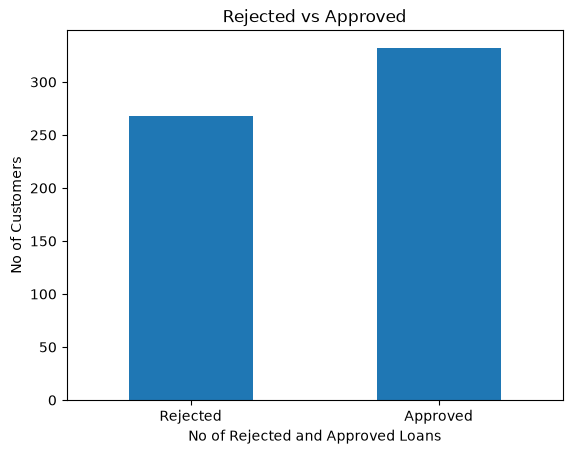

In [19]:
df["loan_approved"].value_counts().sort_index().plot(kind = "bar")
plt.title("Rejected vs Approved")
plt.xlabel("No of Rejected and Approved Loans")
plt.ylabel("No of Customers")
plt.xticks([0,1],["Rejected", "Approved"], rotation = 0)
plt.show()

In [23]:
features = ["age", "annual_income_lakh", "credit_score", "loan_amount_lakh", "existing_emis"]

X = df[features]
y = df["loan_approved"]

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape)
print(X_test.shape)

(450, 5)
(150, 5)


In [25]:
# Feature Scaling
# StandardScaler
# Transform the features values based on their mean closer to 0 and standard deviation closer to 1
# fit_transform()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

pd.DataFrame(X_train_scaled, columns = features).head().round(2)

,age,annual_income_lakh,credit_score,loan_amount_lakh,existing_emis
0,1.65,0.82,0.57,-0.96,1.47
1,-1.18,-0.93,0.06,-1.26,-1.44
2,-0.24,0.51,-0.92,0.80,-0.27
3,-0.67,-0.52,-0.01,-0.26,0.31
4,0.28,-0.93,0.40,-0.72,-0.86


In [26]:
# Sigmoid Function
# score(z/x) --- passed to sigmoid function --- 0 to 1 -- result(Threshold value 0.4) -- model predict the group. If greater than 0.4 Approved.

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [27]:
y_pred = model.predict(X_test_scaled)
prediction_table = pd.DataFrame({
    "Actual" : y_test,
    "Predicted": y_pred
})
prediction_table.head(10)

,Actual,Predicted
110,1,1
419,1,1
565,0,0
77,1,0
181,0,0
284,1,0
10,1,1
469,1,1
78,0,0
349,1,1


In [33]:
# Create a sample score to understand sigmoid function

scores = [-5, -2, 0, 2, 5]

for score in scores:
    # Sigmoid Formula
    probability = 1 / (1 + np.exp(-score))
    print("Score: ", score, "= Probability: ", round(probability, 2))

Score:  -5 = Probability:  0.01
Score:  -2 = Probability:  0.12
Score:  0 = Probability:  0.5
Score:  2 = Probability:  0.88
Score:  5 = Probability:  0.99


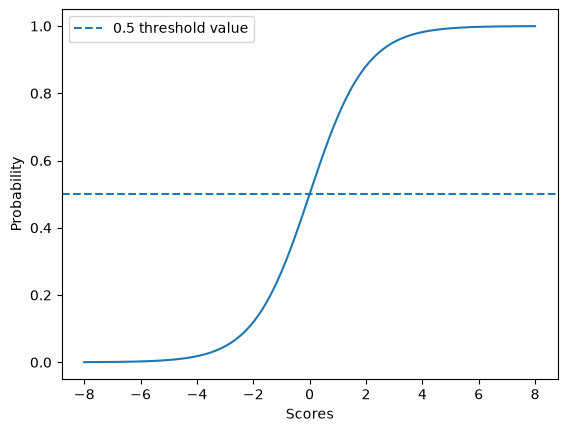

In [38]:
x = np.linspace(-8, 8, 200)

prob = 1 / (1 + np.exp(-x))
plt.plot(x, prob)

plt.axhline(0.5, linestyle = "--", label = "0.5 threshold value")
plt.xlabel("Scores")
plt.ylabel("Probability")
plt.legend()
plt.show()

In [51]:
# Classification Model Evaluation

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [45]:
acc = accuracy_score(y_test, y_pred)
print(f"Logistic Regression Accuracy: {acc: .2%}")

Logistic Regression Accuracy:  84.67%


In [49]:
cm = confusion_matrix(y_test, y_pred, labels = [0, 1])
pd.DataFrame(
    cm,
    index = ["Actual Rejected", "Actual Approvals"],
    columns = ["Predicted Rejection", "Predicted Approvals"]
)

,Predicted Rejection,Predicted Approvals
Actual Rejected,52,2
Actual Approvals,21,75


In [ ]:
# Total Approval: 150
# Correct: 52+75 = 127
# Incorrect: 21+2 = 23

# model acccuracy = (100/150) * 127

In [50]:
# Classification Report
print(classification_report(
    y_test, y_pred,
    labels = [0,1],
    target_names = ["Rejected", "Approved"],
    zero_division = 0
))

              precision    recall  f1-score   support

    Rejected       0.71      0.96      0.82        54
    Approved       0.97      0.78      0.87        96

    accuracy                           0.85       150
   macro avg       0.84      0.87      0.84       150
weighted avg       0.88      0.85      0.85       150



In [ ]:
# Precision - Out of all prediction how many are correctly predicted
# Recall - Out of all prediction to a particular class, how many are correctly predicted
# F1 Score - Higher F1 Score means balance is good. Balance between precision and recall
# Support - No of prediction in each class 